# Lab 1.1 · Linear layers, matrix multiplication, and ReLU

**15–20 minutes · CPU · Python standard library**

## How to work through this notebook

Read the worked example, run the setup, then complete the exercises in order. Replace each `return None` placeholder with your code and run the cell below to check your result. Use the wrap-up to explain the output in your own words.

## Concepts and worked example

A linear layer computes one weighted sum per output and adds a bias. Think of a sample as a row of measurements. Each column of the weight matrix answers a different question about those same measurements.

With input `[2, 4]`, weights `[[3, 1], [-1, 2]]`, and bias `[1, -2]`, the first output is `2×3 + 4×(-1) + 1 = 3`. The second is `2×1 + 4×2 - 2 = 8`. The row index picks an input feature and the column index picks an output. The same weights and bias apply to every sample.

A batch stacks samples into rows, so `(batch, input) @ (input, output)` produces `(batch, output)`. The inner dimensions have to match. The outer dimensions tell you how many rows and columns you get. A tensor library can execute this operation with a matrix multiplication kernel. Here we use loops to expose the arithmetic.

ReLU computes `max(0, x)` for each hidden value. Composing two affine layers gives another affine map with a constant slope. ReLU can switch a hidden feature on or off as the input crosses zero, which allows different slopes in different regions.

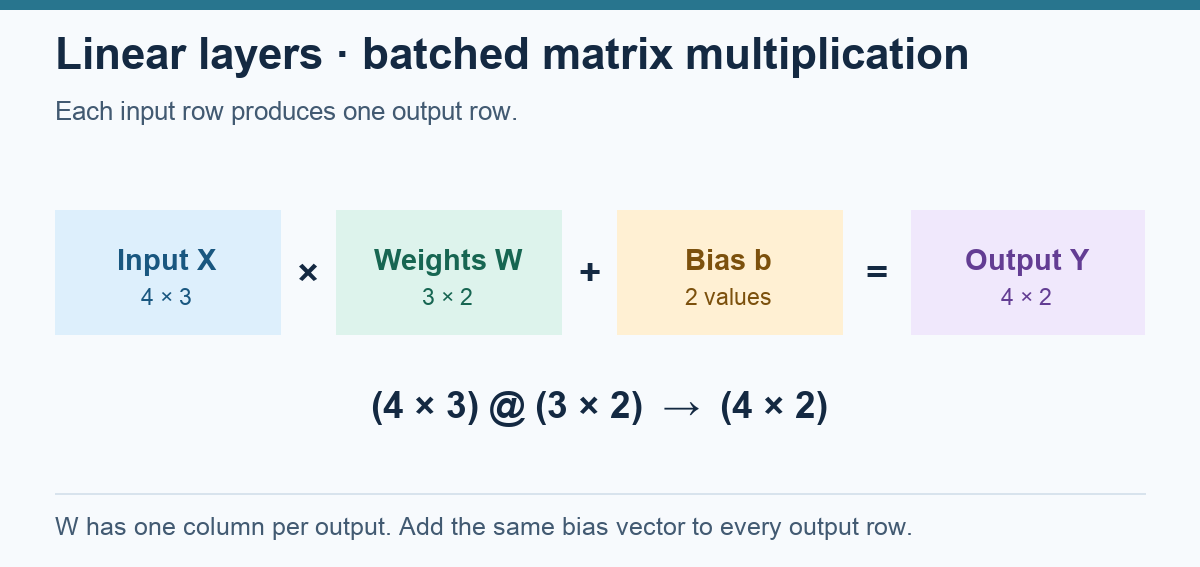

## Exercise map

1. **Build a linear layer** — Work through one output by hand, then implement the same calculation for every output column.
2. **Process a batch** — Predict the output shape, then implement a matrix product and add the bias to each row.
3. **Add ReLU** — Implement the activation and compare two networks with the same weights, one with ReLU between the layers.

[Open the lab guide](README.md) for the exercise checklist.

In [ ]:
inputs = [[2, -1, 3], [0, 1, 2], [-1, 0, 1], [1, 1, 1]]
weights = [[1, 0], [2, -1], [-1, 2]]
bias = [1, -2]


def check(actual, expected):
    if actual is None:
        print("Complete the implementation, then rerun this check.")
        return
    assert actual == expected, f"Expected {expected}, got {actual}"
    print("PASS:", actual)

## Exercise 1. Build a linear layer

For the first input, calculate the first output by hand using the first column of weights and the first bias. Then implement both outputs. For each output index, multiply each feature by the weight in that column, sum the products, and add the corresponding bias. The parameters use matching dimensions throughout this lab.

**Implementation hint** — For each output index, use weights[i][j] for input feature i and add bias[j] once, after the sum.

**After running the check** — The zero-input case isolates the bias. The single-output case checks that your loop works for a different output width.

In [ ]:
def linear_one(features, weights, bias):
    # TODO: Return one dot product plus bias per output.
    return None

In [ ]:
check(linear_one(inputs[0], weights, bias), [-2, 5])
check(linear_one([0, 0, 0], weights, bias), bias)
check(linear_one([1, 2, 3], [[1], [0], [0]], [-1]), [0])

## Exercise 2. Process a batch

Each row of `inputs` is a sample. Each column of `weights` contains the coefficients for one output. Predict the shape of their product. Then implement the product by taking a dot product between every input row and every column of `weights` and adding the bias for that column.

**Implementation hint** — Make the sample loop the outer loop. For every sample, build an output row using the same indexing as Exercise 1.

**After running the check** — The result must agree with applying your first function independently to each input row. Each row is one sample.

In [ ]:
print("X shape:", (len(inputs), len(inputs[0])))
print("W shape:", (len(weights), len(weights[0])))
print("W:", weights)


def linear_batch(samples, weights, bias):
    # Hint: For output j, use weights[i][j] for input feature i.
    # TODO: Return one output row per sample.
    return None

In [ ]:
batch_result = linear_batch(inputs, weights, bias)
expected_batch = [[-2, 5], [1, 1], [-1, 0], [3, -1]]
check(batch_result, expected_batch)
check(linear_batch(inputs[:1], weights, bias), expected_batch[:1])
if batch_result is not None and linear_one(inputs[0], weights, bias) is not None:
    check(batch_result, [linear_one(row, weights, bias) for row in inputs])
    print("Output shape:", (len(batch_result), len(batch_result[0])))

## Exercise 3. Add ReLU

Implement elementwise ReLU on a list, then run the comparison. The hidden layer maps a scalar input `x` to `[x, -x]`. The output layer sums those two values.

Predict the outputs at `x = -2` and `x = 2`, both with and without ReLU. What happens to the slope at zero?

**Implementation hint** — Try ReLU on [-2, 3] first. Then trace the pair [x, -x] through the activation and sum the two surviving values.

**After running the check** — Look at the two hidden values before and after ReLU. The output bends at zero because a different hidden value survives on each side.

In [ ]:
def relu(values):
    # TODO: Clamp each value below zero to zero.
    return None


check(relu([-3, 0, 2]), [0, 0, 2])

In [ ]:
points = [-2, -1, 0, 1, 2]
hidden_rows = [linear_one([x], [[1, -1]], [0, 0]) for x in points]

if hidden_rows[0] is None or relu([-1]) is None:
    print("Complete linear_one and relu to compare the networks.")
else:
    without_relu = [linear_one(row, [[1], [1]], [0])[0] for row in hidden_rows]
    with_relu = [linear_one(relu(row), [[1], [1]], [0])[0] for row in hidden_rows]

    print("x     without ReLU     with ReLU")
    for x, plain, activated in zip(points, without_relu, with_relu):
        print(f"{x:>2} {plain:>16} {activated:>13}")

    check(without_relu, [0, 0, 0, 0, 0])
    check(with_relu, [2, 1, 0, 1, 2])

## Wrap up

- Which dimension changes when you double the batch size? Which dimensions stay fixed?
- Why can't a single affine layer reproduce the ReLU network's output for all real inputs?
- If you add one to the second bias in Exercise 2, which entries in the batch output should change? Make the change and run the layer again.